# Identifikasi Dataset 2: Klasifikasi Multikelas
**Dataset:** Date Fruit Datasets (7 jenis kurma)

## Keterangan dataset
- **Sumber:** Murat Koklu, Ramazan Kursun, Yavuz Selim Taspinar, Ilkay Cinar (2021), *Classification of Date Fruits into Genetic Varieties Using Image Analysis*, Mathematical Problems in Engineering. Unduh dari halaman dataset Murat Koklu (muratkoklu.com/datasets) atau Kaggle ("Date Fruit Datasets").
- **Jenis data:** **tabular numerik** hasil ekstraksi 898 gambar kurma (fitur morfologi, bentuk, dan warna). File yang diberikan berisi fitur, bukan gambar mentah.
- **Label:** 7 jenis kurma: Barhee, Deglet Nour, Sukkary, Rotab Mozafati, Ruthana, Safawi, Sagai.
- **Tujuan:** memprediksi jenis kurma dari fitur citranya.

In [1]:
import os
import pandas as pd

CSV  = "Date_Fruit_Datasets.csv"
XLSX = "Date_Fruit_Datasets.xlsx"   # nama file hasil ekstrak zip dari sumber

if os.path.exists(CSV):
    df = pd.read_csv(CSV)
elif os.path.exists(XLSX):
    df = pd.read_excel(XLSX)        # butuh: pip install openpyxl
    df.to_csv(CSV, index=False)     # simpan versi CSV untuk dikumpulkan
else:
    raise FileNotFoundError("Unduh dataset dari sumber, ekstrak, lalu taruh file .xlsx di folder ini.")

print("Kolom:", list(df.columns))
df.head()

Kolom: ['AREA', 'PERIMETER', 'MAJOR_AXIS', 'MINOR_AXIS', 'ECCENTRICITY', 'EQDIASQ', 'SOLIDITY', 'CONVEX_AREA', 'EXTENT', 'ASPECT_RATIO', 'ROUNDNESS', 'COMPACTNESS', 'SHAPEFACTOR_1', 'SHAPEFACTOR_2', 'SHAPEFACTOR_3', 'SHAPEFACTOR_4', 'MeanRR', 'MeanRG', 'MeanRB', 'StdDevRR', 'StdDevRG', 'StdDevRB', 'SkewRR', 'SkewRG', 'SkewRB', 'KurtosisRR', 'KurtosisRG', 'KurtosisRB', 'EntropyRR', 'EntropyRG', 'EntropyRB', 'ALLdaub4RR', 'ALLdaub4RG', 'ALLdaub4RB', 'Class']


,AREA,PERIMETER,MAJOR_AXIS,MINOR_AXIS,ECCENTRICITY,EQDIASQ,SOLIDITY,CONVEX_AREA,EXTENT,ASPECT_RATIO,...,KurtosisRR,KurtosisRG,KurtosisRB,EntropyRR,EntropyRG,EntropyRB,ALLdaub4RR,ALLdaub4RG,ALLdaub4RB,Class
0,422163.0,2378.908,837.8484,645.6693,0.6373,733.1539,0.9947,424428.0,0.7831,1.2976,...,3.2370,2.9574,4.2287,-5.919126e+10,-5.071421e+10,-3.992237e+10,58.7255,54.9554,47.8400,BERHI
1,338136.0,2085.144,723.8198,595.2073,0.5690,656.1464,0.9974,339014.0,0.7795,1.2161,...,2.6228,2.6350,3.1704,-3.423307e+10,-3.746260e+10,-3.147779e+10,50.0259,52.8168,47.8315,BERHI
2,526843.0,2647.394,940.7379,715.3638,0.6494,819.0222,0.9962,528876.0,0.7657,1.3150,...,3.7516,3.8611,4.7192,-9.394835e+10,-7.473822e+10,-6.031121e+10,65.4772,59.2860,51.9378,BERHI
3,416063.0,2351.210,827.9804,645.2988,0.6266,727.8378,0.9948,418255.0,0.7759,1.2831,...,5.0401,8.6136,8.2618,-3.207431e+10,-3.206093e+10,-2.957501e+10,43.3900,44.1259,41.1882,BERHI
4,347562.0,2160.354,763.9877,582.8359,0.6465,665.2291,0.9908,350797.0,0.7569,1.3108,...,2.7016,2.9761,4.4146,-3.998097e+10,-3.598004e+10,-2.559328e+10,52.7743,50.9080,42.6666,BERHI


## Pisahkan fitur (X) dan label (y)

In [2]:
label_col = df.select_dtypes("object").columns[0]   # satu-satunya kolom kategorik
X = df.drop(columns=label_col)   # data fitur
y = df[label_col]                # data label

print("Kolom label     :", label_col)
print("Jumlah data     :", df.shape[0])
print("Jumlah variabel :", df.shape[1], f"({X.shape[1]} fitur + 1 label)")
print("Fitur           :", list(X.columns))

Kolom label     : Class
Jumlah data     : 898
Jumlah variabel : 35 (34 fitur + 1 label)
Fitur           : ['AREA', 'PERIMETER', 'MAJOR_AXIS', 'MINOR_AXIS', 'ECCENTRICITY', 'EQDIASQ', 'SOLIDITY', 'CONVEX_AREA', 'EXTENT', 'ASPECT_RATIO', 'ROUNDNESS', 'COMPACTNESS', 'SHAPEFACTOR_1', 'SHAPEFACTOR_2', 'SHAPEFACTOR_3', 'SHAPEFACTOR_4', 'MeanRR', 'MeanRG', 'MeanRB', 'StdDevRR', 'StdDevRG', 'StdDevRB', 'SkewRR', 'SkewRG', 'SkewRB', 'KurtosisRR', 'KurtosisRG', 'KurtosisRB', 'EntropyRR', 'EntropyRG', 'EntropyRB', 'ALLdaub4RR', 'ALLdaub4RG', 'ALLdaub4RB']


C:\Users\Fauzan\AppData\Local\Temp\ipykernel_9800\508680796.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  label_col = df.select_dtypes("object").columns[0]   # satu-satunya kolom kategorik


In [3]:
df.info()
print("Missing value:", int(df.isna().sum().sum()))

<class 'pandas.DataFrame'>
RangeIndex: 898 entries, 0 to 897
Data columns (total 35 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   AREA           898 non-null    float64
 1   PERIMETER      898 non-null    float64
 2   MAJOR_AXIS     898 non-null    float64
 3   MINOR_AXIS     898 non-null    float64
 4   ECCENTRICITY   898 non-null    float64
 5   EQDIASQ        898 non-null    float64
 6   SOLIDITY       898 non-null    float64
 7   CONVEX_AREA    898 non-null    float64
 8   EXTENT         898 non-null    float64
 9   ASPECT_RATIO   898 non-null    float64
 10  ROUNDNESS      898 non-null    float64
 11  COMPACTNESS    898 non-null    float64
 12  SHAPEFACTOR_1  898 non-null    float64
 13  SHAPEFACTOR_2  898 non-null    float64
 14  SHAPEFACTOR_3  898 non-null    float64
 15  SHAPEFACTOR_4  898 non-null    float64
 16  MeanRR         898 non-null    float64
 17  MeanRG         898 non-null    float64
 18  MeanRB         898 no

Class
DOKOL     204
SAFAVI    199
ROTANA    166
DEGLET     98
SOGAY      94
IRAQI      72
BERHI      65
Name: count, dtype: int64


<Axes: title={'center': 'Distribusi label'}, xlabel='Class'>

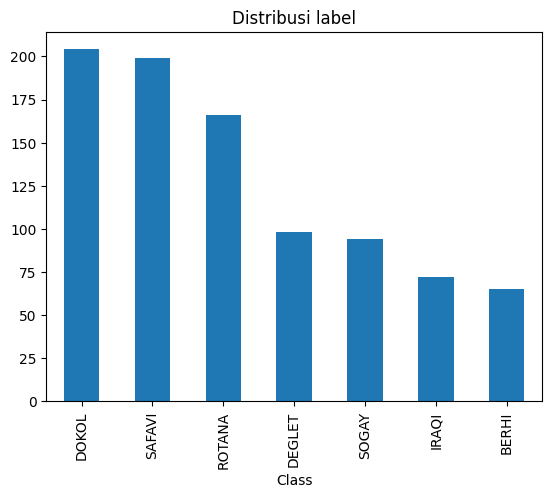

In [4]:
print(y.value_counts())
y.value_counts().plot(kind="bar", title="Distribusi label")

## Kesimpulan jenis klasifikasi

In [5]:
n_kelas = y.nunique()
if n_kelas == 2:
    jenis = "Klasifikasi Biner"
elif n_kelas > 2:
    jenis = "Klasifikasi Multikelas"
print(f"Label '{label_col}' punya {n_kelas} kelas: {sorted(y.unique())}")
print("Kesimpulan:", jenis)

Label 'Class' punya 7 kelas: ['BERHI', 'DEGLET', 'DOKOL', 'IRAQI', 'ROTANA', 'SAFAVI', 'SOGAY']
Kesimpulan: Klasifikasi Multikelas


**Kesimpulan:** Dataset ini **Klasifikasi Multikelas**. Hanya ada **1 kolom label** dengan **7 kelas** jenis kurma, dan setiap data masuk ke tepat satu kelas. Jenis datanya tabular numerik (fitur hasil ekstraksi gambar).